<a href="https://colab.research.google.com/github/giuliavalcu/ML-Seminar-ValcuGiulia/blob/main/Tema_Laborator_3_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Temă LP3 — Preprocesarea datelor (Titanic)

**Timp de lucru: maximum 15 minute** · lucru individual

Aplicați tehnicile din LP3 pe un set de date nou: **Titanic** — informații despre pasagerii navei (vârstă, sex, preț bilet, port de îmbarcare, punte) și dacă au supraviețuit (`survived`).

| Sarcina | Tema | Timp |
| --- | --- | --- |
| 1 | Valori lipsă: diagnostic și eliminare pe bază de prag | ~3 min |
| 2 | Imputarea valorilor lipsă | ~3 min |
| 3 | Asimetrie și transformare logaritmică | ~3 min |
| 4 | Outlieri (regula IQR) | ~3 min |
| 5 | Encoding și scalare | ~3 min |

> 💡 Completați celulele marcate `# TODO`. Nu e nevoie de cod perfect — contează să înțelegeți ce face fiecare pas.

### Pregătire — rulați celula (nu necesită modificări)

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

titanic = sns.load_dataset('titanic')
df = titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked', 'deck']].copy()
df.head()

,survived,pclass,sex,age,fare,embarked,deck
0,0,3,male,22.0,7.2500,S,NaN
1,1,1,female,38.0,71.2833,C,C
2,1,3,female,26.0,7.9250,S,NaN
3,1,1,female,35.0,53.1000,S,C
4,0,3,male,35.0,8.0500,S,NaN


## Sarcina 1 — Valori lipsă (~3 min)

**1.1** Calculați procentul de valori lipsă pentru fiecare coloană, sortat descrescător.

**1.2** Eliminați coloanele cu **mai mult de 50%** valori lipsă. Care coloană dispare?

In [16]:
# TODO 1.1 — procentul de valori lipsă pe coloană
missing_percent = (df.isnull().sum() / len(df)) * 100
print("Procentul de valori lipsa pe fiecare coloana:")
print(missing_percent.sort_values(ascending=False))

# TODO 1.2 — eliminați coloanele cu > 50% valori lipsă
# Determinam coloanele care depasesc pragul de 50%
columns_to_drop = missing_percent[missing_percent > 50].index
print(f"\nColoanele care vor fi eliminate (au > 50% valori lipsa): {list(columns_to_drop)}")

df = df.drop(columns=columns_to_drop)
print("\nColoanele ramase in dataset:")
print(df.columns.tolist())

Procentul de valori lipsa pe fiecare coloana:
deck        77.216611
age         19.865320
embarked     0.224467
sex          0.000000
pclass       0.000000
survived     0.000000
fare         0.000000
dtype: float64

Coloanele care vor fi eliminate (au > 50% valori lipsa): ['deck']

Coloanele ramase in dataset:
['survived', 'pclass', 'sex', 'age', 'fare', 'embarked']


## Sarcina 2 — Imputarea valorilor lipsă (~3 min)

**2.1** Imputați `age` cu **mediana** și `embarked` cu **valoarea cea mai frecventă** (modul).

**2.2** Verificați că nu mai există valori lipsă și comparați deviația standard a lui `age` înainte și după imputare. *(salvați înainte de imputare: `age_inainte = df['age'].copy()`)*

In [17]:
# TODO 2.1 — imputare age (mediană) și embarked (mod)
age_inainte = df['age'].copy()

# Imputare age cu mediana
median_age = df['age'].median()
df['age'] = df['age'].fillna(median_age)

# Imputare embarked cu modul (valoarea cea mai frecventa)
most_frequent_embarked = df['embarked'].mode()[0]
df['embarked'] = df['embarked'].fillna(most_frequent_embarked)

# TODO 2.2 — verificare + comparație deviație standard
missing_after = df.isnull().sum()
print("Valori lipsa dupa imputare:")
print(missing_after)

std_inainte = age_inainte.std()
std_dupa = df['age'].std()
print(f"\nDeviatia standard pentru age INAINTE de imputare: {std_inainte:.4f}")
print(f"Deviatia standard pentru age DUPA imputare: {std_dupa:.4f}")

Valori lipsa dupa imputare:
survived    0
pclass      0
sex         0
age         0
fare        0
embarked    0
dtype: int64

Deviatia standard pentru age INAINTE de imputare: 14.5265
Deviatia standard pentru age DUPA imputare: 13.0197


## Sarcina 3 — Asimetrie și transformare logaritmică (~3 min)

**3.1** Calculați skewness-ul variabilei `fare`.

**3.2** Creați coloana `log_fare = np.log1p(fare)` și calculați skewness-ul ei. A ajutat transformarea?

**3.3** Desenați cele două histograme una lângă alta.

Skewness (asimetrie) initial pentru fare: 4.7873
Skewness (asimetrie) pentru log_fare: 0.3949
A ajutat transformarea? Da, distributia este mult mai simetrica (skewness apropiat de 0)


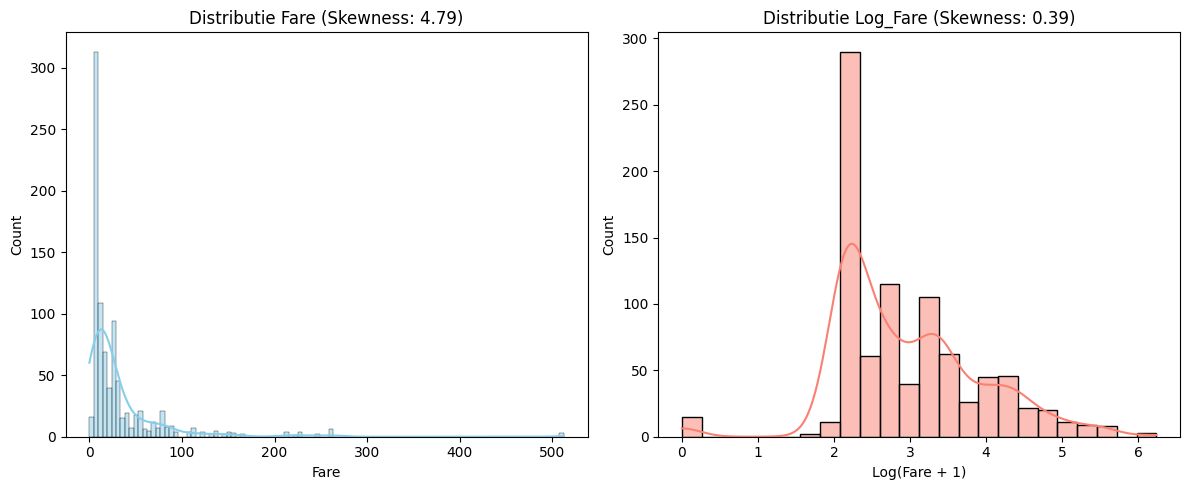

In [18]:
# TODO 3.1 — skewness fare
skew_fare = df['fare'].skew()
print(f"Skewness (asimetrie) initial pentru fare: {skew_fare:.4f}")

# TODO 3.2 — coloana log_fare + skewness
df['log_fare'] = np.log1p(df['fare'])
skew_log_fare = df['log_fare'].skew()
print(f"Skewness (asimetrie) pentru log_fare: {skew_log_fare:.4f}")
print(f"A ajutat transformarea? {'Da, distributia este mult mai simetrica (skewness apropiat de 0)' if abs(skew_log_fare) < abs(skew_fare) else 'Nu'}")

# TODO 3.3 — două histograme
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df['fare'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title(f"Distributie Fare (Skewness: {skew_fare:.2f})")
axes[0].set_xlabel("Fare")

sns.histplot(df['log_fare'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title(f"Distributie Log_Fare (Skewness: {skew_log_fare:.2f})")
axes[1].set_xlabel("Log(Fare + 1)")

plt.tight_layout()
plt.show()

## Sarcina 4 — Outlieri cu regula IQR (~3 min)

**4.1** Calculați limitele `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]` pentru `fare` și numărați outlierii.

**4.2** Limitați (clip) valorile extreme într-o coloană nouă, `fare_capped`, și afișați maximul înainte și după.

In [19]:
# TODO 4.1 — limite IQR + număr de outlieri
Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[(df['fare'] < lower_limit) | (df['fare'] > upper_limit)]
print(f"Limita inferioara: {lower_limit:.4f}")
print(f"Limita superioara: {upper_limit:.4f}")
print(f"Numar de outlieri detectati pentru 'fare': {len(outliers)}")

# TODO 4.2 — fare_capped (clip) + maxim înainte/după
df['fare_capped'] = df['fare'].clip(lower=lower_limit, upper=upper_limit)

print(f"\nValoarea maxima INAINTE de capping: {df['fare'].max():.4f}")
print(f"Valoarea maximă DUPA capping: {df['fare_capped'].max():.4f}")

Limita inferioara: -26.7240
Limita superioara: 65.6344
Numar de outlieri detectati pentru 'fare': 116

Valoarea maxima INAINTE de capping: 512.3292
Valoarea maximă DUPA capping: 65.6344


## Sarcina 5 — Encoding și scalare (~3 min)

**5.1** Aplicați One-Hot Encoding pe `sex` și `embarked` (cu `drop_first=True`, `dtype=int`).

**5.2** Standardizați `age` și `fare_capped` cu `StandardScaler`. Verificați că media ≈ 0 și deviația standard ≈ 1.

In [20]:
# TODO 5.1 — One-Hot Encoding pentru sex și embarked
df = pd.get_dummies(df, columns=['sex', 'embarked'], drop_first=True, dtype=int)
print("Dataset dupa One-Hot Encoding:")
print(df.head())

# TODO 5.2 — StandardScaler pentru age și fare_capped + verificare medie/std
scaler = StandardScaler()

# Aplicăm scalarea
df[['age', 'fare_capped']] = scaler.fit_transform(df[['age', 'fare_capped']])

print("\nVerificare dupa Standardizare (StandardScaler):")
print(f"Media pentru age: {df['age'].mean():.4f} (ar trebui sa fie ~0)")
print(f"Deviatia standard pentru age: {df['age'].std():.4f} (ar trebui sa fie ~1)")
print(f"Media pentru fare_capped: {df['fare_capped'].mean():.4f} (ar trebui sa fie ~0)")
print(f"Deviatia standard pentru fare_capped: {df['fare_capped'].std():.4f} (ar trebui sa fie ~1)")

Dataset dupa One-Hot Encoding:
   survived  pclass   age     fare  log_fare  fare_capped  sex_male  \
0         0       3  22.0   7.2500  2.110213       7.2500         1   
1         1       1  38.0  71.2833  4.280593      65.6344         0   
2         1       3  26.0   7.9250  2.188856       7.9250         0   
3         1       1  35.0  53.1000  3.990834      53.1000         0   
4         0       3  35.0   8.0500  2.202765       8.0500         1   

   embarked_Q  embarked_S  
0           0           1  
1           0           0  
2           0           1  
3           0           1  
4           0           1  

Verificare dupa Standardizare (StandardScaler):
Media pentru age: 0.0000 (ar trebui sa fie ~0)
Deviatia standard pentru age: 1.0006 (ar trebui sa fie ~1)
Media pentru fare_capped: 0.0000 (ar trebui sa fie ~0)
Deviatia standard pentru fare_capped: 1.0006 (ar trebui sa fie ~1)


## Întrebare de reflecție (1–2 propoziții)

*De ce am imputat `age`, dar am eliminat `deck`?*

*Răspunsul tău:*

Am eliminat coloana **`deck`** deoarece avea un procentaj mult prea mare de valori lipsa (~77%). Reconstruirea sau imputarea unei proportii atat de mari de date ar fi introdus un nivel ridicat de incertitudine și bias în model.

In schimb, coloana **`age`** avea doar aproximativ ~20% valori lipsa. Aceasta este o cantitate rezonabila de date lipsa, care poate fi salvata prin imputare (folosind mediana) pentru a pastra informatiile valoroase din celelalte coloane ale randurilor respective fara a compromite sever integritatea setului de date.